✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.
NLP Model Loaded Successfully!
SVM Model Trained Successfully!
Training Samples: 15

INPUT TEXT:

Steve Jobs founded Apple.
Google acquired YouTube.
Sundar Pichai leads Google.
Apple is based in California.


EXTRACTED RELATIONSHIPS:


,Entity 1,Entity 1 Type,Relationship,Entity 2,Entity 2 Type,Dependency Path
0,Steve Jobs,PERSON,FOUNDED,Apple,ORG,WORD:jobs -> UP:nsubj -> WORD:found -> DOWN:do...
1,Google,ORG,ACQUIRED,YouTube,PRODUCT,WORD:google -> UP:nsubj -> WORD:acquire -> DOW...
2,Apple,ORG,LOCATED_IN,California,GPE,WORD:apple -> UP:nsubjpass -> WORD:base -> DOW...


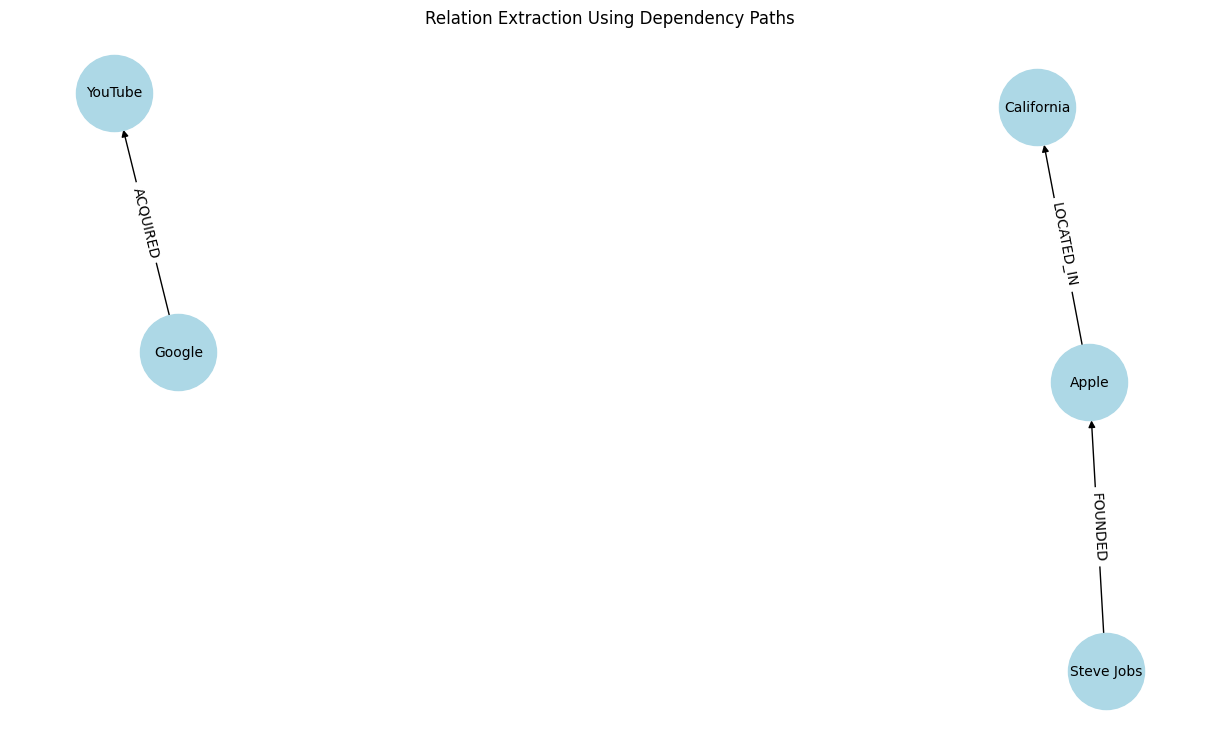


RELATION EXTRACTION COMPLETED!


In [1]:
# ============================================================
# RELATION EXTRACTION USING DEPENDENCY PATHS
# AND SUBSEQUENCE KERNELS
# ============================================================

!pip install -q spacy scikit-learn pandas networkx matplotlib
!python -m spacy download en_core_web_sm -q

import spacy
import itertools
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

from sklearn.feature_extraction import DictVectorizer
from sklearn.svm import SVC

# 1. LOAD NLP MODEL
nlp = spacy.load("en_core_web_sm")
print("NLP Model Loaded Successfully!")

# 2. DEPENDENCY PATH EXTRACTION
def get_dependency_path(ent1, ent2):

    t1, t2 = ent1.root, ent2.root

    ancestors1 = [t1] + list(t1.ancestors)
    ancestors2 = [t2] + list(t2.ancestors)

    common = set(ancestors1) & set(ancestors2)

    if not common:
        return None

    lca = min(
        common,
        key=lambda t: ancestors1.index(t) + ancestors2.index(t)
    )

    path = []
    current = t1

    while current != lca:
        path.extend(["WORD:" + current.lemma_.lower(),
                     "UP:" + current.dep_])
        current = current.head

    path.append("WORD:" + lca.lemma_.lower())

    downward = []
    current = t2

    while current != lca:
        downward.append(current)
        current = current.head

    for token in reversed(downward):
        path.extend(["DOWN:" + token.dep_,
                     "WORD:" + token.lemma_.lower()])

    return path


# 3. SUBSEQUENCE KERNEL FEATURES
def subsequence_features(sequence, max_length=4, decay=0.5):

    features = {}
    n = len(sequence)

    for length in range(1, min(max_length, n) + 1):
        for indices in itertools.combinations(range(n), length):

            subsequence = tuple(sequence[i] for i in indices)

            span = indices[-1] - indices[0] + 1
            weight = decay ** (span - length)

            features[subsequence] = (
                features.get(subsequence, 0) + weight
            )

    return features


# 4. TRAINING DATASET
training_data = [
    ("Steve Jobs founded Apple.", "Steve Jobs", "Apple", "FOUNDED"),
    ("Bill Gates founded Microsoft.", "Bill Gates", "Microsoft", "FOUNDED"),
    ("Larry Page founded Google.", "Larry Page", "Google", "FOUNDED"),
    ("Elon Musk founded SpaceX.", "Elon Musk", "SpaceX", "FOUNDED"),

    ("Google acquired YouTube.", "Google", "YouTube", "ACQUIRED"),
    ("Microsoft acquired LinkedIn.", "Microsoft", "LinkedIn", "ACQUIRED"),
    ("Facebook acquired Instagram.", "Facebook", "Instagram", "ACQUIRED"),

    ("Sundar Pichai leads Google.", "Sundar Pichai", "Google", "CEO_OF"),
    ("Tim Cook leads Apple.", "Tim Cook", "Apple", "CEO_OF"),

    ("Apple is based in California.", "Apple", "California", "LOCATED_IN"),
    ("Google is based in California.", "Google", "California", "LOCATED_IN"),

    ("Steve Jobs worked at Pixar.", "Steve Jobs", "Pixar", "WORKED_AT"),

    ("Microsoft was founded by Bill Gates.", "Microsoft", "Bill Gates", "FOUNDED_BY"),
    ("YouTube was acquired by Google.", "YouTube", "Google", "ACQUIRED_BY"),

    ("Steve Jobs visited Google.", "Steve Jobs", "Google", "NO_RELATION"),
    ("Bill Gates visited Apple.", "Bill Gates", "Apple", "NO_RELATION"),
    ("Google hired Steve Jobs.", "Google", "Steve Jobs", "NO_RELATION"),
    ("Apple hired Bill Gates.", "Apple", "Bill Gates", "NO_RELATION")
]


# 5. EXTRACT TRAINING FEATURES
X_train = []
y_train = []

for sentence, e1, e2, relation in training_data:

    doc = nlp(sentence)

    ent1 = next((e for e in doc.ents if e.text.lower() == e1.lower()), None)
    ent2 = next((e for e in doc.ents if e.text.lower() == e2.lower()), None)

    if ent1 and ent2:
        path = get_dependency_path(ent1, ent2)

        if path:
            X_train.append(subsequence_features(path))
            y_train.append(relation)


# 6. TRAIN SVM CLASSIFIER
vectorizer = DictVectorizer()
X = vectorizer.fit_transform(X_train)

model = SVC(
    kernel="linear",
    C=1.0,
    class_weight="balanced"
)

model.fit(X, y_train)

print("SVM Model Trained Successfully!")
print("Training Samples:", len(X_train))


# 7. RELATION EXTRACTION
def extract_relations(text):

    doc = nlp(text)
    entities = list(doc.ents)

    results = []

    for ent1, ent2 in itertools.permutations(entities, 2):

        if ent1.sent != ent2.sent:
            continue

        path = get_dependency_path(ent1, ent2)

        if not path:
            continue

        features = subsequence_features(path)
        X_test = vectorizer.transform([features])

        prediction = model.predict(X_test)[0]

        if prediction != "NO_RELATION":

            results.append({
                "Entity 1": ent1.text,
                "Entity 1 Type": ent1.label_,
                "Relationship": prediction,
                "Entity 2": ent2.text,
                "Entity 2 Type": ent2.label_,
                "Dependency Path": " -> ".join(path)
            })

    return pd.DataFrame(results)


# 8. TEST INPUT
test_text = """
Steve Jobs founded Apple.
Google acquired YouTube.
Sundar Pichai leads Google.
Apple is based in California.
"""

print("\nINPUT TEXT:")
print(test_text)

# 9. DISPLAY RESULTS
results = extract_relations(test_text)

print("\nEXTRACTED RELATIONSHIPS:")

if not results.empty:
    display(results)
else:
    print("No relationships found!")


# 10. VISUALIZE RELATIONSHIPS
if not results.empty:

    G = nx.DiGraph()

    for _, row in results.iterrows():
        G.add_edge(
            row["Entity 1"],
            row["Entity 2"],
            label=row["Relationship"]
        )

    plt.figure(figsize=(12, 7))

    pos = nx.spring_layout(G, seed=42)

    nx.draw(
        G, pos,
        with_labels=True,
        node_size=3000,
        node_color="lightblue",
        font_size=10,
        arrows=True
    )

    labels = nx.get_edge_attributes(G, "label")

    nx.draw_networkx_edge_labels(
        G, pos,
        edge_labels=labels
    )

    plt.title("Relation Extraction Using Dependency Paths")
    plt.axis("off")
    plt.show()

print("\nRELATION EXTRACTION COMPLETED!")